# CEC

> Transfer of a CNN for cation exchange capacity (CEC) from OSSL to Fukushima: zero-shot, head-only, fine-tuned, fully fine-tuned and Fukushima-only models, with schedules chosen by cross-validation

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspecdl.all import plot_cv
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`. The outputs come from a local run on an Apple silicon GPU (MPS). `02_transfer` defines the functions used here.

## Data

OSSL MIR spectra on the shared grid, with CEC in cmolc/kg. The models predict `log1p(CEC)`:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('cec_usda.a723_cmolc.kg')
yo = np.log1p(yo.ravel())
Xo.shape

(57062, 1675)

The Fukushima spectra, with CEC in meq/100 g, which equals cmolc/kg. The test set is the Cs137 study's test set:

In [ ]:
#| fukudata
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_CEC'])
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
_, test_ids = cs137_split()
is_test = np.isin(idf, test_ids)
yt = yf[is_test]
Xf.shape, int(is_test.sum())

((1386, 1675), 340)

## Pretraining

The preprocessing is SNV followed by a Savitzky-Golay first derivative, fitted on OSSL and applied to Fukushima. `pretrain` trains on OSSL, or loads the weights of an earlier run. The table shows the last epoch of pretraining, with the R² of the OSSL validation set:

In [ ]:
#| fukudata
pipe = preprocessings()['snv_d1']
Xo_d, Xf_d = pipe.fit_transform(Xo), pipe.transform(Xf)
pretrained = pretrain(Xo_d, yo, 'ossl_cec_snv_d1')
pretrain_history('ossl_cec_snv_d1').iloc[-1].round(3).to_dict()

{'train_loss': 0.037, 'valid_loss': 0.028, 'r2_score': 0.966}

## Schedule

The fully fine-tuned and Fukushima-only models each get their own learning rate and number of epochs, chosen on the Fukushima training samples by 5-fold cross-validation. The test set plays no part. `start` gives each model's starting weights: the pretrained model, or `None` for random weights. The learning rate finder, from each starting point:

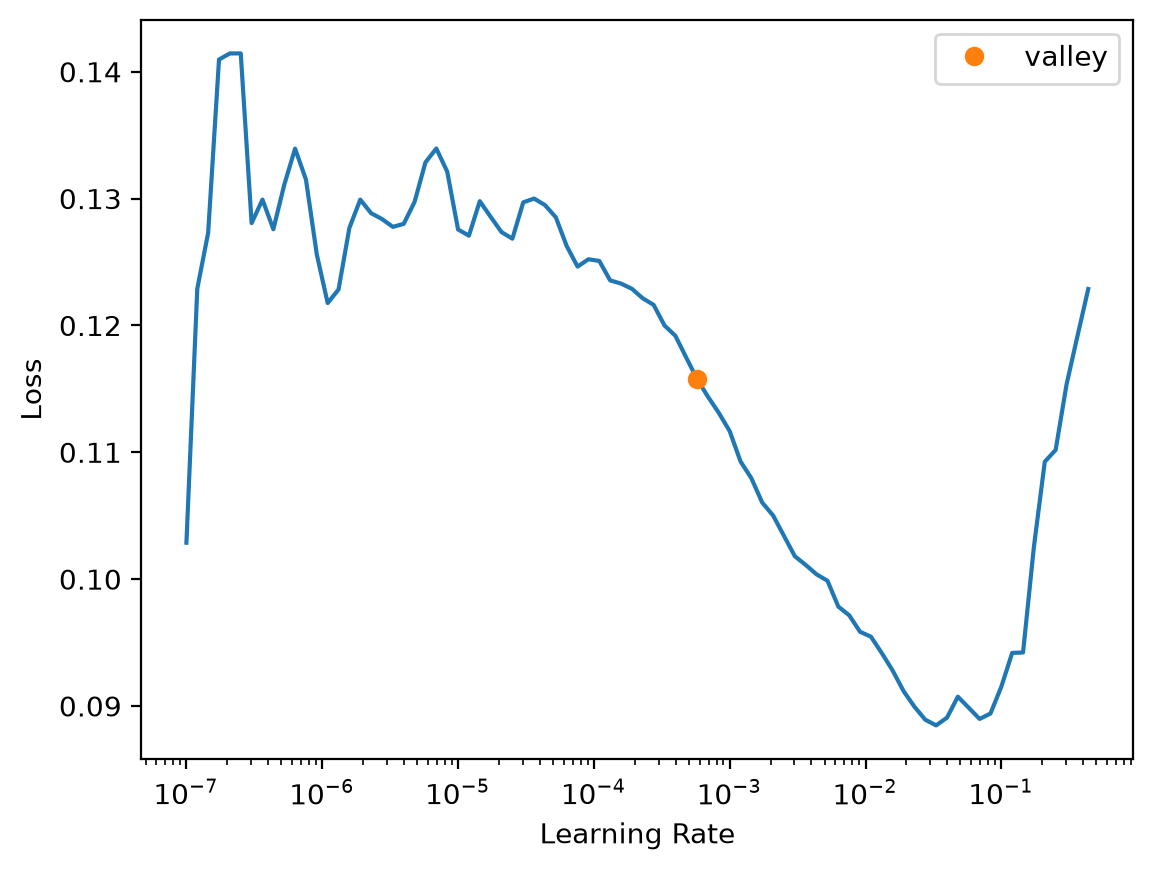

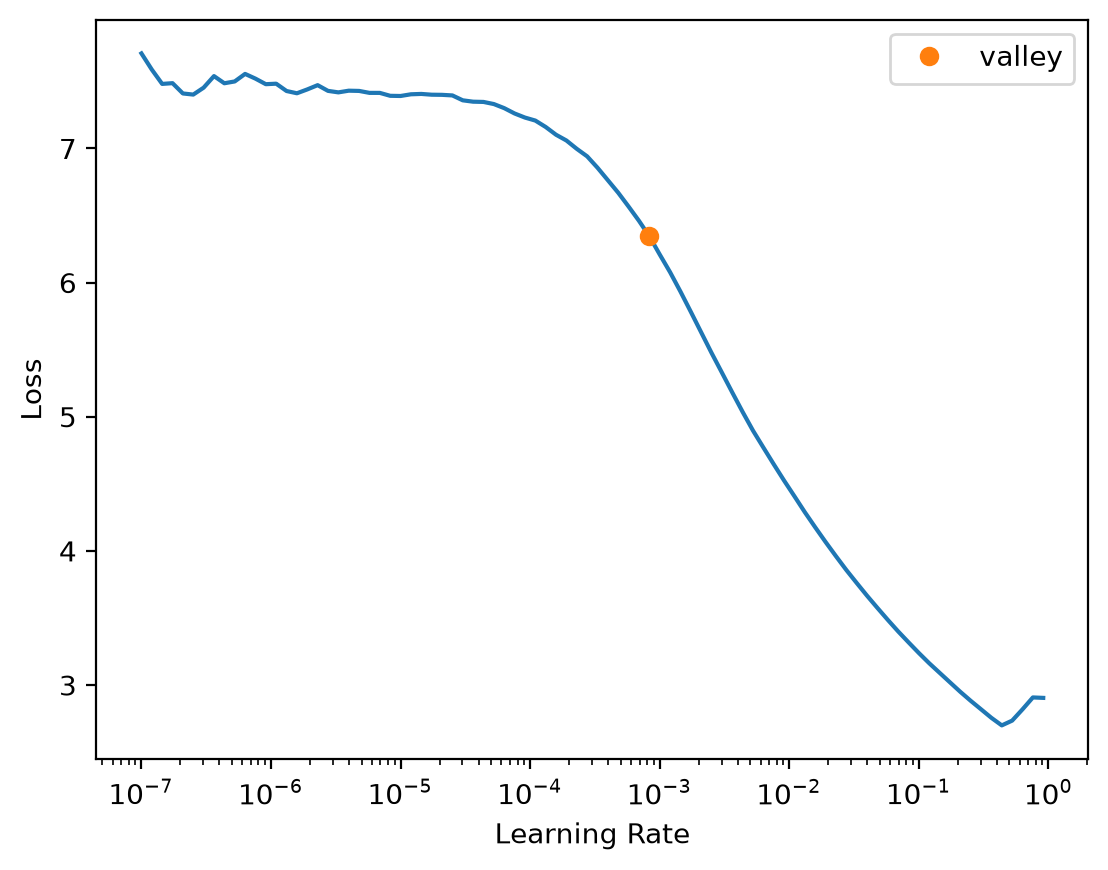

{'fully fine-tuned': 0.0005754399462603033,
 'Fukushima only': 0.0008317637839354575}

In [ ]:
#| fukudata
start = {'fully fine-tuned': pretrained, 'Fukushima only': None}
mslug = {'fully fine-tuned': 'ft', 'Fukushima only': 'scratch'}
{m: float(fuku_lr_find(s, Xf_d, yf, is_test).valley) for m, s in start.items()}

Four learning rates, each with 40 one-cycle epochs. The table gives the validation loss (mean squared error of `log1p`) and R² at the last epoch, as mean and standard deviation over the folds:

In [ ]:
#| fukudata
lrs = [1e-4, 3e-4, 1e-3, 3e-3]
cv = lambda m, lr, ep: cv_curves(start[m], Xf_d, yf, is_test, lr, ep, fname=f'cv_cec_{mslug[m]}_lr{lr:g}_ep{ep}')
lr_res = {(m, lr): cv_final(cv(m, lr, 40)) for m in start for lr in lrs}
best_lr = {m: min(lrs, key=lambda lr: lr_res[m, lr]['valid_loss']) for m in start}
pd.DataFrame(lr_res).T.round(4)

valid_loss  valid_loss sd      R²   R² sd
fully fine-tuned 0.0001      0.0271         0.0042  0.6978  0.0115
                 0.0003      0.0242         0.0049  0.7307  0.0213
                 0.0010      0.0232         0.0058  0.7436  0.0322
                 0.0030      0.0226         0.0063  0.7508  0.0383
Fukushima only   0.0001      0.0381         0.0071  0.5754  0.0413
                 0.0003      0.0325         0.0066  0.6383  0.0398
                 0.0010      0.0285         0.0064  0.6835  0.0388
                 0.0030      0.0266         0.0049  0.7044  0.0194

The learning curves at each model's best learning rate, as mean over folds with a band of ±1 standard deviation:

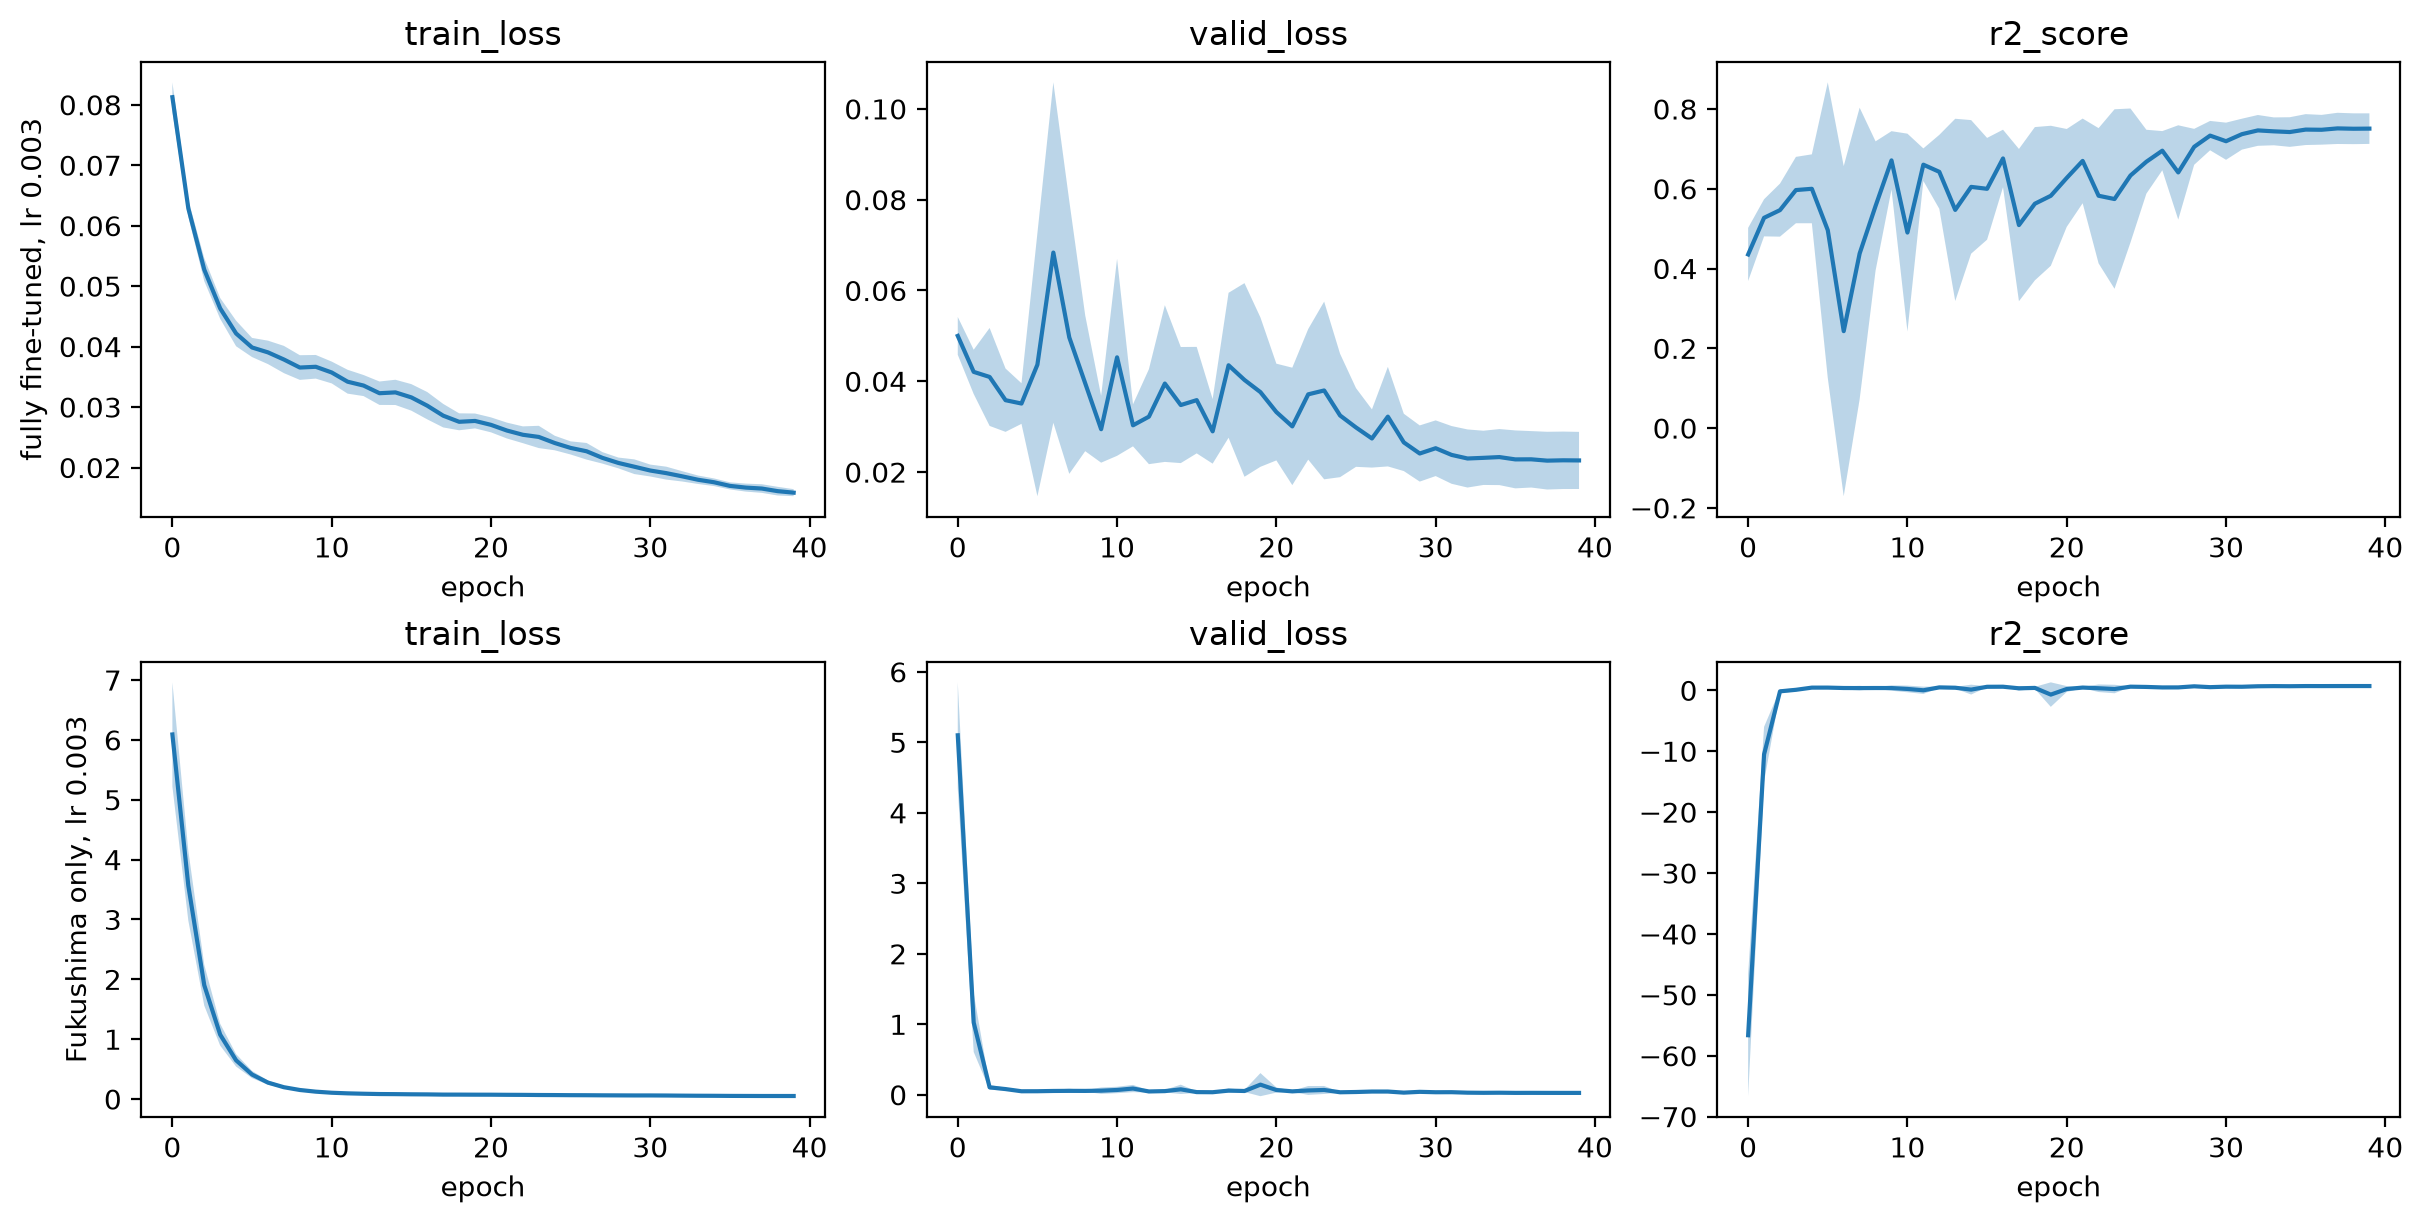

In [ ]:
#| fukudata
fig, axs = plt.subplots(2, 3, figsize=(12, 6), layout='constrained')
for row, m in zip(axs, start):
    plot_cv(cv(m, best_lr[m], 40), axs=row)
    row[0].set_ylabel(f'{m}, lr {best_lr[m]:g}')

Three numbers of epochs, at each model's best learning rate. A one-cycle schedule changes shape with its length, so each count is trained separately:

In [ ]:
#| fukudata
eps = [20, 40, 80]
ep_res = {(m, ep): cv_final(cv(m, best_lr[m], ep)) for m in start for ep in eps}
schedules = {m: (min(eps, key=lambda ep: ep_res[m, ep]['valid_loss']), best_lr[m]) for m in start}
pd.DataFrame(ep_res).T.round(4), schedules

(                     valid_loss  valid_loss sd      R²   R² sd
 fully fine-tuned 20      0.0232         0.0059  0.7434  0.0335
                  40      0.0226         0.0063  0.7508  0.0383
                  80      0.0234         0.0063  0.7407  0.0386
 Fukushima only   20      0.0332         0.0066  0.6304  0.0378
                  40      0.0266         0.0049  0.7044  0.0194
                  80      0.0228         0.0052  0.7472  0.0268,
 {'fully fine-tuned': (40, 0.003), 'Fukushima only': (80, 0.003)})

## Comparison

Each Fukushima model trains with five seeds, the fully fine-tuned and Fukushima-only models with the schedules chosen above. The other models keep their defaults. The table gives the mean and standard deviation over the seeds of R² and correlation `r` of `log1p(CEC)`, and of the RMSE and bias of CEC in cmolc/kg, on the test samples:

In [ ]:
#| fukudata
res, preds = compare({'snv_d1': pretrained}, {'snv_d1': Xf_d}, yf, is_test, schedules=schedules)
summarise(res).round(3)

R²             r  ...          bias       
                                 mean    std   mean  ...    std   mean    std
preprocessing model                                  ...                     
snv_d1        zero-shot        -0.695  0.000  0.572  ...  0.000 -2.994  0.000
              zero-shot AdaBN  -0.646  0.008  0.550  ...  0.030  4.060  0.037
              head only         0.313  0.004  0.610  ...  0.016 -0.314  0.076
              fine-tuned        0.388  0.002  0.647  ...  0.007 -0.273  0.071
              fully fine-tuned  0.735  0.004  0.859  ...  0.015 -0.291  0.062
              Fukushima only    0.709  0.012  0.847  ...  0.065 -0.453  0.214

[6 rows x 8 columns]

For scale, the standard deviation of the test CEC values, in cmolc/kg:

In [ ]:
#| fukudata
round(float(np.expm1(yt).std()), 3)

5.612

Predictions of the first seed against the observed values:

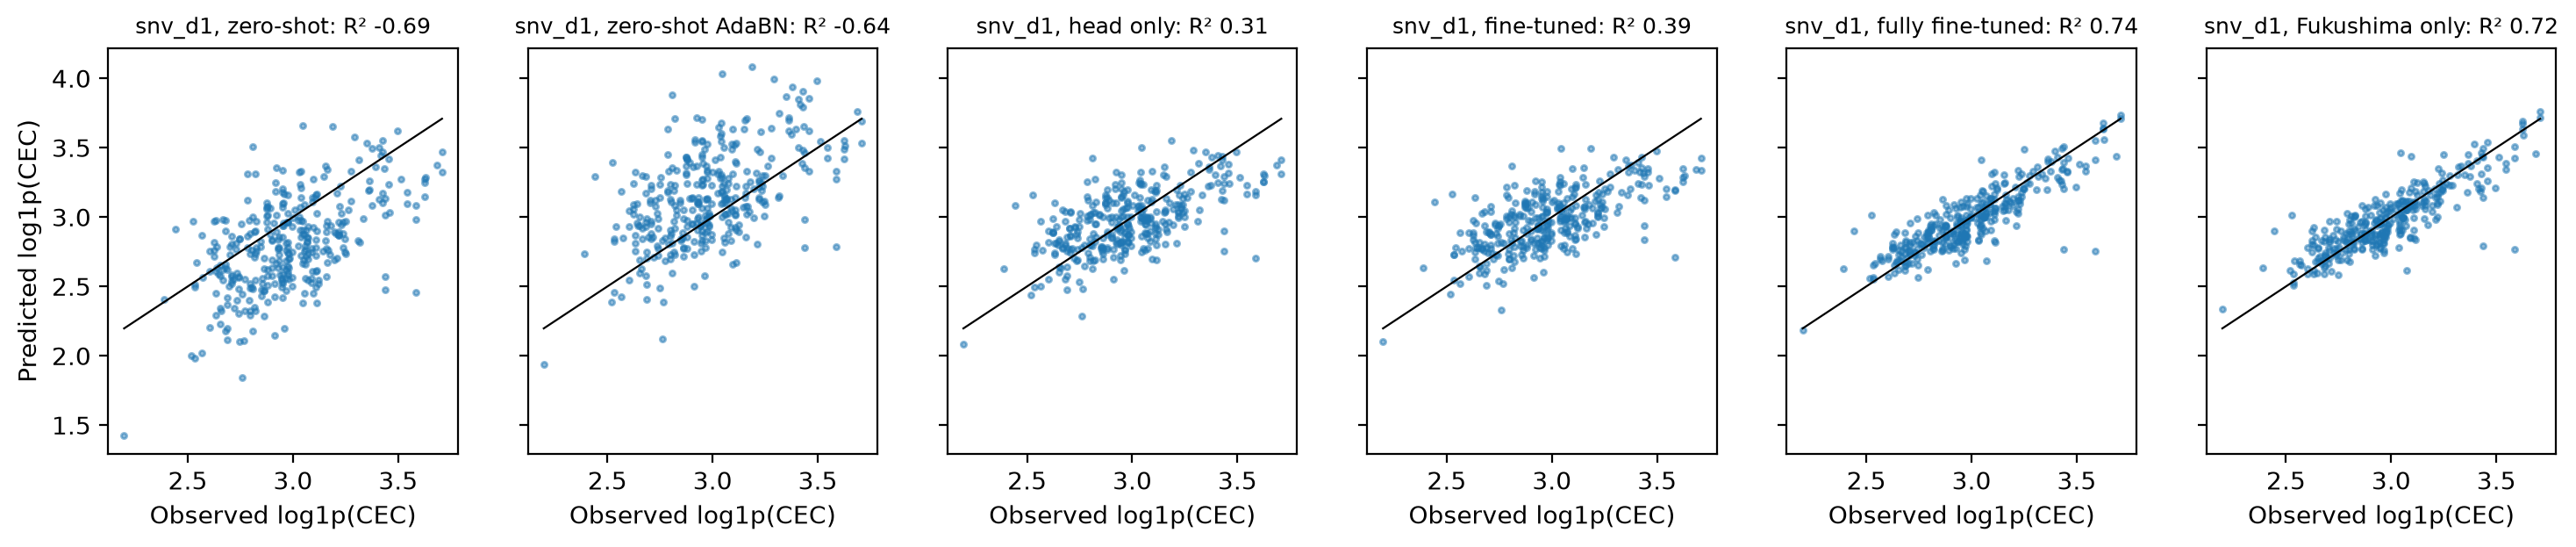

In [ ]:
#| fukudata
plot_preds(preds, yt, label='log1p(CEC)');

## Joint training

One model trains from random weights on all OSSL spectra and the Fukushima training samples together, with the Fukushima samples repeated to make up 25% or 50% of the training set (see `joint_dls`). It uses the pretraining schedule, 20 one-cycle epochs at 1e-3, which was not tuned for joint training. Three seeds per share, scored on the same test set as above:

In [ ]:
#| fukudata
jrows = []
for share in [0.25, 0.5]:
    for s in range(3):
        p = fit_joint(Xo_d, yo, Xf_d, yf, is_test, share, s, fname=f'joint_cec_share{share}_seed{s}')
        jrows.append({'share': share, 'seed': s, **scores(yt, p)})
pd.DataFrame(jrows).groupby('share')[['R²', 'r', 'RMSE', 'bias']].agg(['mean', 'std']).round(3)

R²             r          RMSE          bias       
        mean    std   mean    std   mean    std   mean    std
share                                                        
0.25   0.734  0.010  0.860  0.006  2.746  0.044 -0.325  0.081
0.50   0.720  0.014  0.852  0.009  2.819  0.087 -0.275  0.089

## Checks

The OSSL validation R² covers OSSL's whole CEC range. The pretrained model is scored again on its OSSL validation samples, first all of them, then those within the 5th to 95th percentile of Fukushima CEC:

In [ ]:
#| fukudata
lo, hi = np.quantile(yf, [0.05, 0.95])
np.expm1([lo, hi]).round(2), {k: round(v, 3) for k, v in range_check(Xo_d, yo, pretrained, lo, hi).items()}

(array([11.2 , 30.77]),
 {'n all': 5706,
  'R² all': 0.966,
  'r all': np.float64(0.983),
  'n in range': 2677,
  'R² in range': 0.66,
  'r in range': np.float64(0.857)})

## Error analysis

Mean absolute error of `log1p(CEC)` by soil type, year and measurement batch. Each model's predictions are averaged over the seeds first:

In [ ]:
#| fukudata
props = fuku.source.loc[idf[is_test]]
error_table(preds, yt, props['Soil_type_describe'], 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
Andosols,0.161,0.152,0.112,0.131,44
Forest soil,0.204,0.194,0.074,0.084,27
Glay soil,0.171,0.160,0.104,0.092,6
Lowland soil,0.169,0.158,0.094,0.093,243
Peat soil,0.150,0.133,0.076,0.084,14
Red yellow soil,0.130,0.118,0.080,0.073,6


In [ ]:
#| fukudata
error_table(preds, yt, props['year'].astype(int), 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
2013,0.205,0.195,0.133,0.139,34
2014,0.162,0.139,0.080,0.084,53
2015,0.143,0.138,0.086,0.084,48
2016,0.155,0.147,0.075,0.074,58
2017,0.181,0.167,0.085,0.099,37
2018,0.217,0.204,0.115,0.114,46
2019,0.136,0.132,0.093,0.093,48
2020,0.184,0.175,0.117,0.118,16


In [ ]:
#| fukudata
error_table(preds, yt, sample_batches(idf[is_test]), 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
batch 1,0.193,0.176,0.103,0.11,110
batch 2,0.158,0.150,0.090,0.09,230
